In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def expan(img, cmin, cmax):
    salida = np.zeros_like(img, dtype=np.uint8)
    filas, cols = img.shape
    for i in range(filas):
        for j in range(cols):
            ND = img[i, j]
            if ND <= cmin:
                salida[i, j] = 0
            elif ND >= cmax:
                salida[i, j] = 255
            else:
                salida[i, j] = int(((ND - cmin) * 255) / (cmax - cmin))
    return salida

In [20]:
def corte(img, porc=0.01):
    hist = cv2.calcHist([img], [0], None, [256], [0,256]).ravel().astype(int)
    total_pix = img.size
    corte_pix = int(total_pix * porc)
    acumulado = 0
    cmin = 0
    for i in range(256):
        acumulado += hist[i]
        if acumulado > corte_pix:
            cmin = i
            break
    acumulado = 0
    cmax = 255
    for i in range(255, -1, -1):
        acumulado += hist[i]
        if acumulado > corte_pix:
            cmax = i
            break

    print(f"NDcortemin = {cmin}, NDcortemax = {cmax}")
    return expan(img, cmin, cmax)

NDcortemin = 11, NDcortemax = 181


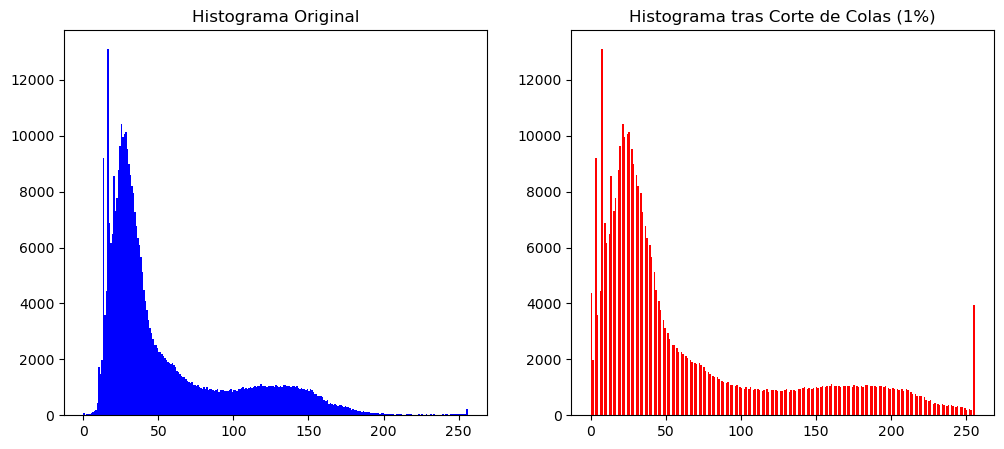

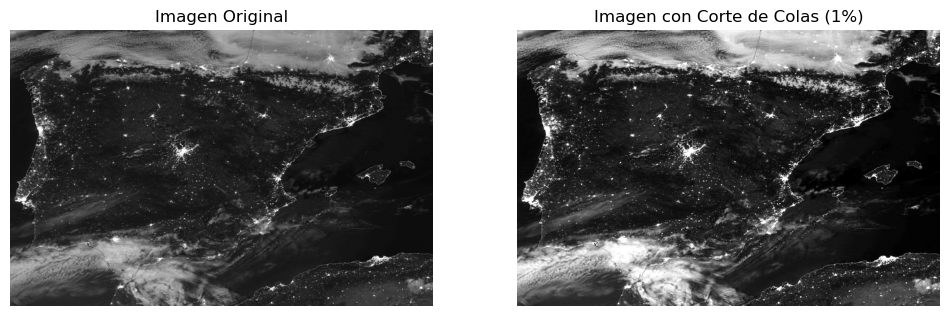

In [21]:
img = cv2.imread("satelite.jpg", cv2.IMREAD_GRAYSCALE)
img_corte = corte(img, 0.01)

#Histogramas
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.hist(img.ravel(), bins=256, range=(0,256), color="blue")
plt.title("Histograma Original")
plt.subplot(1,2,2)
plt.hist(img_corte.ravel(), bins=256, range=(0,256), color="red")
plt.title("Histograma tras Corte de Colas (1%)")
plt.show()

#Imágenes
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_corte, cmap="gray")
plt.title("Imagen con Corte de Colas (1%)")
plt.axis("off")
plt.show()